# Libraries

In [28]:
import numpy as np
from astropy.io import fits
import matplotlib.pyplot as plt
from matplotlib import colors
import matplotlib.colors as colors
from scipy.optimize import curve_fit
from astropy.timeseries import LombScargle
from scipy.ndimage import uniform_filter1d
import scipy.ndimage

# Functions

In [35]:
def get_stokes_i(data, scantime, dt):
    spec = []
    mjds = []
    phi=0 #reference angle for Q-U reference frame

    #we need to convert the data to total intensity
    #since the data are recorded in circular polarization
    for i in range(len(data)):
        spectrum=[]

        mjds.append(data[i][0])

        #extract polarization parameters
        lcp=np.array(data[i][1][0])
        rcp=np.array(data[i][1][1])
        COS=np.array(data[i][1][2])
        SIN=np.array(data[i][1][3])

        I=lcp+rcp
        Q=np.cos(phi)*COS-np.sin(phi)*SIN
        U=np.sin(phi)*COS+np.cos(phi)*SIN
        V=lcp-rcp


        spec.append(I)#append STOKES I (Q=1,U=2,V=3)

    length = int(scantime // dt)
    spec = np.array(spec)

    return spec[-length:, :]


# Define the Gaussian function
def gauss(x, A, B, C, D):
    y = A*np.exp(-1*B*(x-C)**2)+D
    return y


# Does a simple bandpass calibration by dividing all data by the average spectrum
def calibrate_bandpass(spec):
    for i in range(len(spec[0])):
        add_count=0
        for j in range(len(spec)):
            add_count+=spec[j][i]
        corr_factor=add_count/len(spec)
        for j in range(len(spec)):
            spec[j][i]= spec[j][i] / corr_factor

    return spec


# Remove noise cal effect
def remove_noise_cal(spec):

    for j in range(len(spec[0])):

        #seperate the two/four phases
        bin1=[]
        bin2=[]
        count=2
        switch=True
        for i in range(len(spec)):
            if count==0:
                switch=not switch
                count=2
            if switch:
                bin1.append(spec[i][j])
            elif not switch:
                bin2.append(spec[i][j])
            count-=1

        fit1 = np.full(len(bin1),np.average(bin1))
        fit2 = np.full(len(bin2),np.average(bin2))

        bin1=bin1-fit1
        bin2=bin2-fit2

        final_time=[]
        i = 0
        while i < len(bin1):
            final_time.append(bin1[i])
            if not i + 1 >= len(bin1):
                final_time.append(bin1[i + 1])
            if not i >= len(bin2):
                final_time.append(bin2[i])
            if not i + 1 >= len(bin2):
                final_time.append(bin2[i + 1])
            i += 2

        for i in range(len(spec)):
            spec[i][j] = final_time[i]
    return spec


# remove source
def remove_source(spec, isLC = False, noisecal = False, showPlots=False):
    if isLC:
        averaged_spectrum = spec
    else:
        averaged_spectrum = np.mean(spec, axis=1)

    try:
        parameters, covariance = curve_fit(
            gauss,
            np.arange(len(averaged_spectrum)),
            np.array(averaged_spectrum),
            p0=np.asarray([0.1, 1 / 100, len(averaged_spectrum) / 2, np.average(averaged_spectrum)]),
            maxfev=2000,
            bounds=([0, 0, 0, -np.inf], [np.inf, np.inf, len(averaged_spectrum), np.inf])
        )
    except Exception as e:
        parameters = [0, 0, 0, 0]
        print(f"Curve fitting failed: {e}")

    fit_A1, fit_B1, fit_C1, fit_D1 = parameters

    fit = gauss(np.arange(len(averaged_spectrum)), fit_A1, fit_B1, fit_C1, fit_D1)

    if showPlots:
        plt.plot(np.arange(len(averaged_spectrum)), averaged_spectrum, color="lightgray", label="Averaged Spectrum")
        plt.plot(np.arange(len(fit)), fit, color="blue", label="Gaussian Fit")
        plt.legend()
        plt.show()

    spec = (spec.T - fit).T

    return spec


# Returns x and y values of Lightcurve from Spectra
def get_lc(spec, dt, plotlim=None):
    if plotlim is None:
        plotlim = []
    if len(plotlim)>0:
        ind_min=int(plotlim[0]/dt)
        ind_max=int(plotlim[1]/dt)
    else:
        ind_min=0
        ind_max= len(spec) - 1

    t = np.linspace(0, (len(spec) - 1) * dt, len(spec))
    t = t[ind_min:ind_max]
    intens = np.nanmean(spec, axis=1)
    intens = intens[ind_min:ind_max]

    return t,intens


def get_anomalies(spec, treshold_factor=2):
    laplacian_kernel = np.array([[0,  1, 0],
                             [1, -4, 1],
                             [0,  1, 0]])
    filtered_spec = scipy.ndimage.convolve(spec, laplacian_kernel)

    # Define a threshold value
    threshold = np.mean(filtered_spec) + treshold_factor * np.std(filtered_spec)
    # Create a binary mask of anomalies
    anomalies = np.abs(filtered_spec) > threshold

    return filtered_spec #anomalies


# Plot all results in one single plot
def plot_results(t, intens, filtered_intens, boxcar_width, snr, spec, freqs, stime):
    # Create a figure with 1 row and 2 columns for subplots

    half_boxcar = boxcar_width // 2
    peak_index = np.argmax(filtered_intens)

    fig, ax = plt.subplots(1, 2, figsize=(12, 5))  # Adjust figsize as needed

    # Plot 1
    ax[0].plot(t, intens, label='Original', color='lightgray')
    # Mark peak position
    ax[0].plot(t, filtered_intens, label='Filtered', linestyle='-')
    ax[0].axvline(t[peak_index], color='red', linestyle=':', label='Peak')
    # mark signal region
    if snr != 0:
        ax[0].axvline(t[peak_index - half_boxcar], color='black', linestyle='--', label='Signal region')
        ax[0].axvline(t[peak_index + half_boxcar], color='black', linestyle='--')
    ax[0].set_xlabel('Time [s]')
    ax[0].set_ylabel('Counts')
    ax[0].legend()

    # Plot 2
    im = ax[1].imshow(spec, norm=colors.LogNorm(), extent=[np.min(freqs), np.max(freqs), stime, 0], aspect='auto')
    fig.colorbar(im, ax=ax[1])  # Add colorbar to the second plot
    ax[1].set_xlabel("Frequency [GHz]")
    ax[1].set_ylabel("Time [s]")

    x_min, x_max = ax[1].get_xlim()
    y_coord_1 = (scantime / len(spectra)) * (peak_index - half_boxcar)
    y_coord_2 = (scantime / len(spectra)) * peak_index
    y_coord_3 = (scantime / len(spectra)) * (peak_index + half_boxcar)

    # mark peak position and signal region
    ax[1].text(x_min, y_coord_1, '-', color='black', fontsize=20, ha='center', va='center')
    ax[1].text(x_min, y_coord_2, '-', color= 'red', fontsize=20, ha='center', va='center')
    ax[1].text(x_min, y_coord_3, '-', color='black', fontsize=20, ha='center', va='center')

    # Adjust the layout to make room for the text at the top
    plt.subplots_adjust(top=0.85)
    fig.suptitle(f'Boxcar Width: {boxcar_width:.2f} --> {boxcar_width * dt:.4f}s\nSignal-to-Noise Ratio (SNR): {snr:.2f}', fontsize=14)
    # Display the plots
    plt.tight_layout()  # Adjusts the subplot params so that the subplot(s) fits in to the figure area.
    plt.show()


# Plot Spectrun (--> average over time)
def plot_spectrum(spec, freqs):
    plt.plot(freqs, np.average(spec, axis=0))
    plt.xlabel("Frequency [GHz]")
    plt.ylabel("Counts")
    plt.show()


# Plot Lightcurve (--> average over frequencies) and return times and intensities
def plot_lc(spec, periodogram=False, doScatter=False, plotlim=None, isLC=False):
    if plotlim is None:
        plotlim = []
    if len(plotlim)>0:
        ind_min=int(plotlim[0]/dt)
        ind_max=int(plotlim[1]/dt)
    else:
        ind_min=0
        ind_max= len(spec) - 1

    times=np.linspace(0, (len(spec) - 1) * dt, len(spec))
    times=times[ind_min:ind_max]
    if isLC:
        intensities = spec
    else:
        intensities=np.nanmean(spec, axis=1)
        intensities=intensities[ind_min:ind_max]
    if doScatter:
        plt.scatter(times,intensities)
    else:
        plt.plot(times,intensities)
    plt.xlabel("Time [s]")
    plt.ylabel("Counts")
    plt.show()

    if periodogram:
        freq, p_ls = LombScargle(times, np.nan_to_num(intensities)).autopower(minimum_frequency=0.000000001,
                                         maximum_frequency=10,
                                         normalization='psd',
                                         samples_per_peak=50)
        plt.plot(freq,p_ls)
        plt.yscale("log")
        plt.xlabel("Frequency")
        plt.ylabel("Spectral Power")
        plt.show()

        return freq, p_ls

    return times,intensities


# Create waterfall plot
def plot_waterfall(spec, stime, freqs, masked=False):

    # optional: mask some frequency band
    if masked:
        mask=np.zeros(spec.shape)
        mask[:, len(spec[1]) // 2 - 2:len(spec[1]) // 2 + 2]=1
        spec=np.ma.masked_array(spec, mask)

    plt.imshow(spec, norm=colors.LogNorm(), extent=[np.min(freqs), np.max(freqs), stime, 0], aspect="auto")
    plt.colorbar()
    plt.xlabel("Frequency [GHz]")
    plt.ylabel("Time [s]")
    plt.savefig('foo.png', bbox_inches='tight')
    plt.show()


def plot_mask_waterfall(anomalies, spec, stime, freqs, save_path=None):
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))

    # Plot 1: Edge Mask
    im1 = ax[0].imshow(anomalies, cmap="gray", aspect="auto")
    ax[0].set_xlabel('Frequency [GHz]')
    ax[0].set_ylabel('Time [s]')

    cbar2 = fig.colorbar(im1, ax=ax[0])

    # Plot 2: Waterfall Plot (Spectrogram)
    im2 = ax[1].imshow(spec+1, norm=colors.LogNorm(), extent=[np.min(freqs), np.max(freqs), stime, 0], aspect='auto')
    ax[1].set_xlabel("Frequency [GHz]")
    ax[1].set_ylabel("Time [s]")

    # Add colorbar to the right of the second plot
    cbar2 = fig.colorbar(im2, ax=ax[1])

    #plt.subplots_adjust(wspace=0.3)  # Increase the space between the two subplots
    plt.tight_layout()

    # Save as vector if save_path is provided
    if save_path:
        plt.savefig(save_path, format='pdf')  # You can also use 'pdf' or 'eps'

    plt.show()


# Define Gaussian function with noise
def gauss_with_noise(x, A, B, C, D):
    y = A*np.exp(-1*B*(x-C)**2)+D

    # Identify the indices within the two sigma region
    two_sigma_indices = np.where(np.abs(x - C) <= 2 * B)[0]

    # Add noise within the two sigma region
    noise_std_dev = 0.2*A  # Standard deviation of the noise
    noise = np.random.normal(0, noise_std_dev, len(two_sigma_indices))
    y[two_sigma_indices] += noise

    return y


# Add noise to spectra
def add_rfi(spec, num_rfi, noise_level=100):
    spec_max = np.max(spec)

    for i in range(num_rfi):
        # Number of frequencies
        width = np.random.randint(1, 5)
        # Amount of time
        length = np.random.randint(300, len(spec))
        intensity = spec_max * noise_level
        # Position on the frequency axis
        position_width = np.random.randint(1, len(spec[0]) - width - 1)
        # Position on the time axis
        position_length = np.random.randint(1, len(spec) - 1)*2
        #print(position_width)
        #print(position_length)
        x = np.arange(len(spec))
        # Generate RFI (a noisy Gauss curve)
        box = gauss_with_noise(x, intensity, 1 / length, position_length / 2, 0)

        # Apply RFI to previously generated position
        for i in range(position_width, position_width+width):
            spec[:, i] += box

    return spec


def get_edge_mask(spectra):
    # Apply a Gaussian filter to smooth the data
    smoothed_spectra = scipy.ndimage.gaussian_filter(spectra, sigma=1)

    # Define a 2D Laplacian kernel
    laplacian_kernel = np.array([[0,  -1, 0],
                                [-1, 4, -1],
                                [0,  -1, 0]])

    # Apply the Laplacian convolution to the smoothed data
    filtered_spectra = scipy.ndimage.convolve(smoothed_spectra, laplacian_kernel)

    # Calculate the threshold value for anomaly detection
    threshold = np.mean(filtered_spectra) + 2 * np.std(filtered_spectra)

    # Create a binary mask of anomalies
    anomalies = np.abs(filtered_spectra) > threshold

    return anomalies


def plot_edge_mask(edge_mask, stime, freqs, save_path):
    # Plot the edge mask as a waterfall
    plt.imshow(edge_mask, cmap="gray", aspect="auto")
    #plt.colorbar(label="Edge Presence")
    plt.xlabel("Frequency [GHz]")
    plt.ylabel("Time [s]")
    if save_path:
        plt.savefig(save_path, format='pdf', bbox_inches='tight')  # You can also use 'pdf' or 'eps'
    plt.show()


def get_ass(spectra, anomalies):
    # Count rows that have at least one True value
    rows_with_anomalies = np.any(anomalies, axis=1)
    num_rows_with_anomalies = np.sum(rows_with_anomalies)

    # Count columns that have at least one True value
    columns_with_anomalies = np.any(anomalies, axis=0)
    num_columns_with_anomalies = np.sum(columns_with_anomalies)

    # Calculate the effective size considering only rows and columns with anomalies
    effective_size = num_rows_with_anomalies * num_columns_with_anomalies

    try:
        effective_density = np.sum(anomalies) / effective_size
    except Exception as e:
        effective_density = 0

    pai = np.max(np.abs(spectra[anomalies]))

    ass = pai * effective_density # Anomaly Significance Score

    return ass


def get_mmr(spectra,anomalies):
    mean_intensity = np.mean(np.abs(spectra[anomalies]))
    pai = np.max(np.abs(spectra[anomalies]))

    try:
        mmr = pai / mean_intensity
    except Exception as e:
        mmr = 0

    return mmr


def get_snr(spectra,anomalies):
    intensity_std = np.std(spectra)
    pai = np.max(np.abs(spectra[anomalies]))

    try:
        snr = pai / intensity_std
    except Exception as e:
        snr = 0

    return snr


def get_pai(spectra, anomalies):
    pai = np.max(np.abs(spectra[anomalies]))
    return pai

In [30]:
def preprocess(path, num_rfi):
    telamon_data_fits = fits.open(path)
    #Let's extract some important information
    scantime = 25 #scantime in seconds (not included in header)
    dt = 0.015625
    bandwidth = telamon_data_fits[1].header["BANDWID"]
    center_freq = telamon_data_fits[1].header["RESTFREQ"]
    low_freq=center_freq-bandwidth/2
    high_freq=center_freq+bandwidth/2

    #and read out the data
    data = telamon_data_fits[1].data
    #convert data from circular Polarization to StokesI
    spectra = get_stokes_i(data, scantime, dt)

    spectra = add_rfi(spectra,num_rfi)

    #extract some information
    frequencies=np.linspace(low_freq / 1e9, high_freq / 1e9, len(spectra[0]))

    spectra = calibrate_bandpass(spectra)
    spectra = remove_noise_cal(spectra)

    spectra_no_source = remove_source(spectra)
    anomalies = get_edge_mask(spectra_no_source)
    return (anomalies, spectra_no_source, scantime, frequencies)

def prepareMask(filename, save_path):
    anomalies, spectra_no_source, scantime, frequencies = preprocess(filename)
    plot_edge_mask(anomalies, scantime, frequencies, save_path)

def showEdgeMask(filename, num_rfi=0, save_path=None):
    anomalies, spectra_no_source, scantime, frequencies = preprocess(filename, num_rfi)
    print("ASS: ", get_ass(spectra_no_source, anomalies))
    print("MMR: ", get_mmr(spectra_no_source, anomalies))
    print("SNR: ", get_snr(spectra_no_source, anomalies))
    print("PAI: ", get_pai(spectra_no_source, anomalies))
    plot_mask_waterfall(anomalies, spectra_no_source, scantime, frequencies, save_path=None)

# Load Spectra

In [31]:
filename = "DATA_2023-01-24_6789_82-22_subscan2_S20mm-SPECPOL-ARRAYDATA-1.fits" # in fits_files_r, replace with subscan of choice

In [32]:
path = "fits_files_a/" # contains some anomalous subscans

In [33]:
path = "fits_files_r/" # contains random subscans, may also be anomalous

# View Results

Edge Mask Result:

ASS:  5.095694637803126
MMR:  12.94516105919633
SNR:  78.05361524098751
PAI:  38.834336065646895


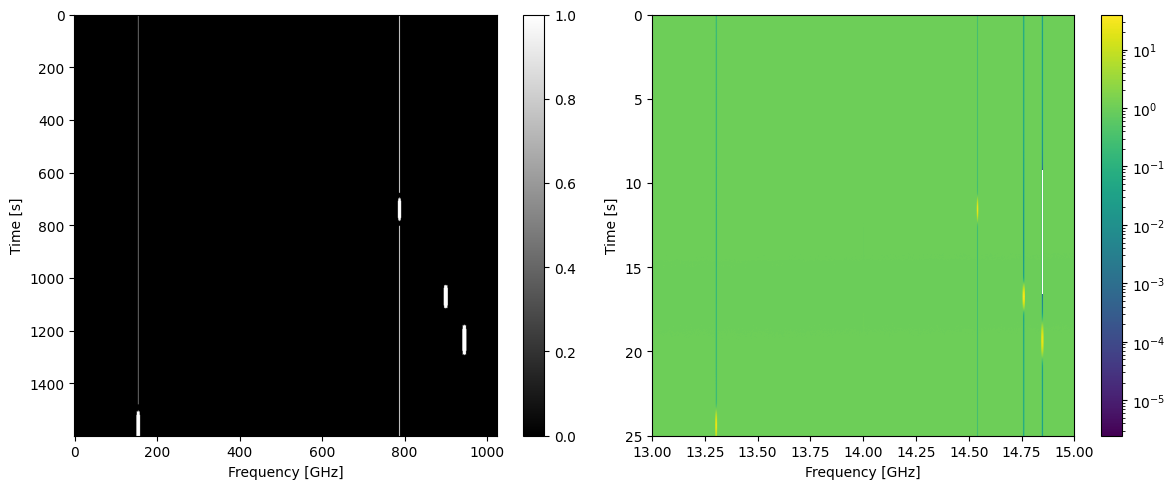

In [36]:
save_path = None # save plot as pdf, ex. "plot1.pdf"
num_rfi = 4 # adds no random RFI if 0
showEdgeMask(path+filename, num_rfi=num_rfi, save_path=save_path)

Step-by-step:

In [37]:
telamon_data_fits = fits.open(path+filename)

In [38]:
telamon_data_fits[1].header

XTENSION= 'BINTABLE'           / binary table extension                         
BITPIX  =                    8 / 8-bit bytes                                    
NAXIS   =                    2 / 2-dimensional binary table                     
NAXIS1  =                16392 / width of table in bytes                        
NAXIS2  =                 1788 / number of rows in table                        
PCOUNT  =                    0 / size of special data area                      
GCOUNT  =                    1 / one data group (required keyword)              
TFIELDS =                    2 / number of fields in each row                   
EXTNAME = 'ARRAYDATA-MBFITS'   / name of this binary table extension            
GRPID1  =                   -1 / EXTVER of Group containing this HDU            
GRPLC1  = '../GROUPING.fits'   / URL of file containing Group                   
LONGSTRN= 'OGIP 1.0'           / The HEASARC Long String Convention may be used.
COMMENT   This FITS file may

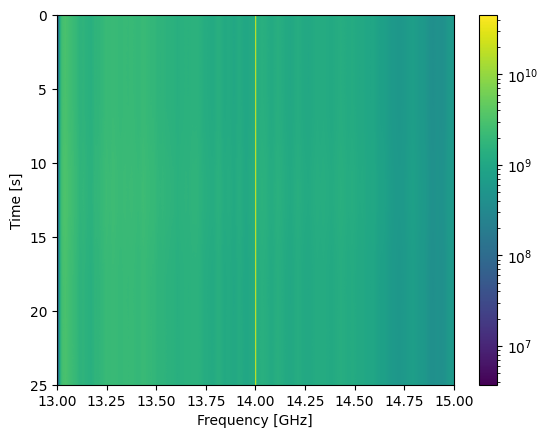

In [39]:
#Let's extract some important information
scantime = 25 #scantime in seconds (not included in header)
dt = 0.015625
bandwidth = telamon_data_fits[1].header["BANDWID"]
center_freq = telamon_data_fits[1].header["RESTFREQ"]
low_freq=center_freq-bandwidth/2
high_freq=center_freq+bandwidth/2

#and read out the data
data = telamon_data_fits[1].data
#convert data from circular Polarization to StokesI
spectra = get_stokes_i(data, scantime, dt)

#extract some information
frequencies=np.linspace(low_freq / 1e9, high_freq / 1e9, len(spectra[0]))
plot_waterfall(spectra, scantime, frequencies)

OPTIONAL: add random RFI

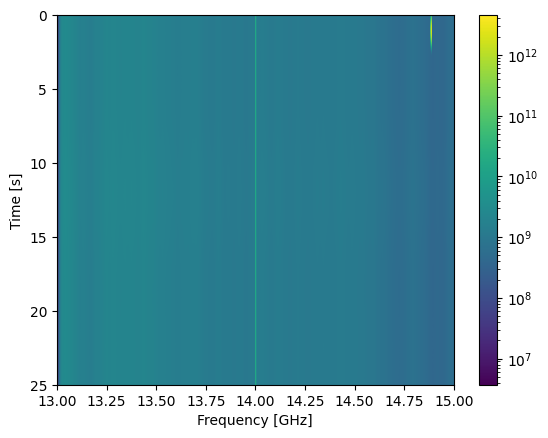

In [40]:
spectra = add_rfi(spectra,num_rfi=1,noise_level=100)
plot_waterfall(spectra, scantime, frequencies)

# Calibrate Spectra

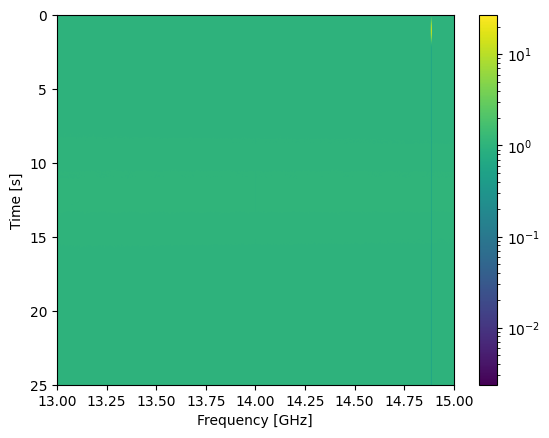

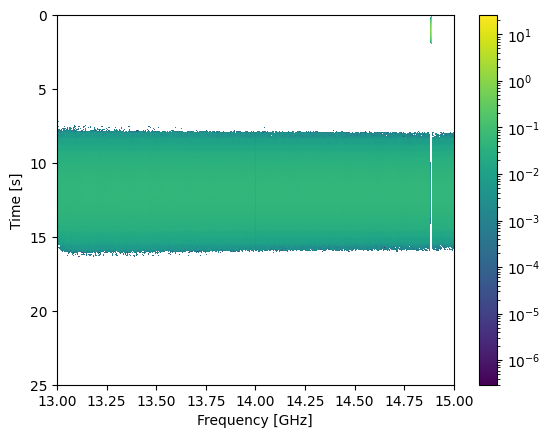

In [41]:
spectra = calibrate_bandpass(spectra)
plot_waterfall(spectra, scantime, frequencies)
spectra = remove_noise_cal(spectra)
plot_waterfall(spectra, scantime, frequencies)

Light Curve with source not removed:

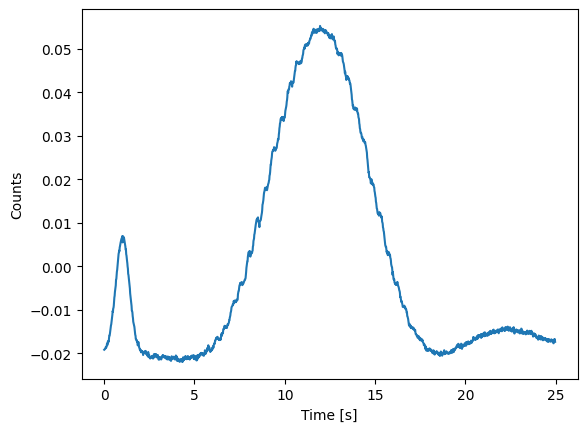

In [42]:
times, intensities = plot_lc(spectra)

# Remove Source

remove source from Ligth Curve:

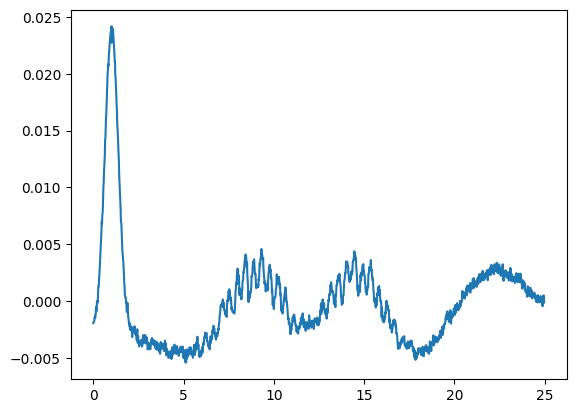

In [43]:
intensities_no_source = remove_source(intensities,isLC=True)
plt.plot(times,intensities_no_source)
plt.show()

OR directly remove source from spectra:

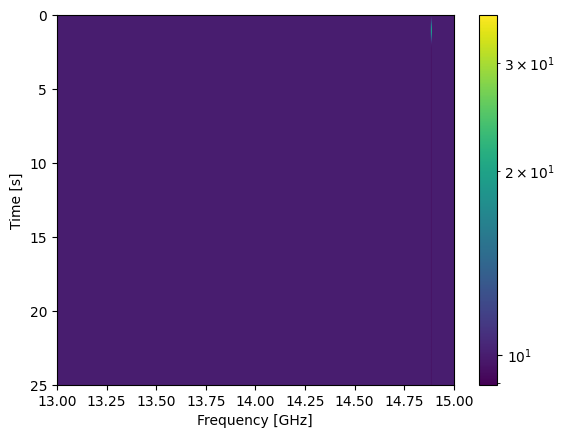

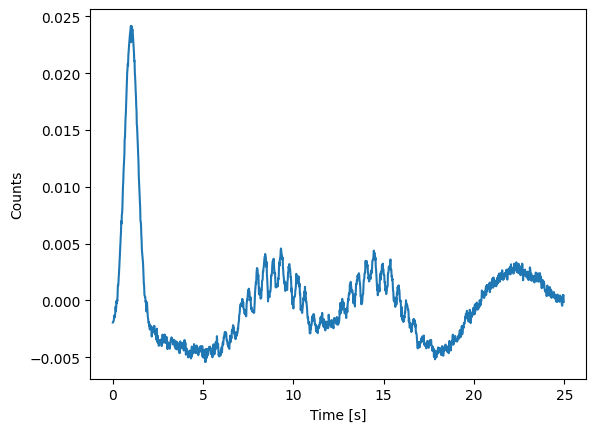

(array([0.0000000e+00, 1.5625000e-02, 3.1250000e-02, ..., 2.4937500e+01,
        2.4953125e+01, 2.4968750e+01]),
 array([-0.00195217, -0.0018715 , -0.00185574, ...,  0.00039353,
         0.0004594 , -0.00014217]))

In [44]:
spectra_no_source = remove_source(spectra, noisecal=True)
plot_waterfall(spectra_no_source + 10, scantime, frequencies)
plot_lc(spectra_no_source)

# Laplace Convolution

In [45]:
# Apply a Gaussian filter to smooth the data
smoothed_spectra = scipy.ndimage.gaussian_filter(spectra, sigma=1)

In [46]:
# Define a 2D Laplacian kernel
laplacian_kernel = np.array([[0,  -1, 0],
                            [-1, 4, -1],
                            [0,  -1, 0]])

In [47]:
# Apply the Laplacian convolution to the smoothed data
filtered_spectra = scipy.ndimage.convolve(smoothed_spectra, laplacian_kernel)

In [48]:
# Calculate the threshold value for anomaly detection
threshold = np.mean(filtered_spectra) + 2 * np.std(filtered_spectra)

In [49]:
# Create a binary mask of anomalies
anomalies = np.abs(filtered_spectra) > threshold

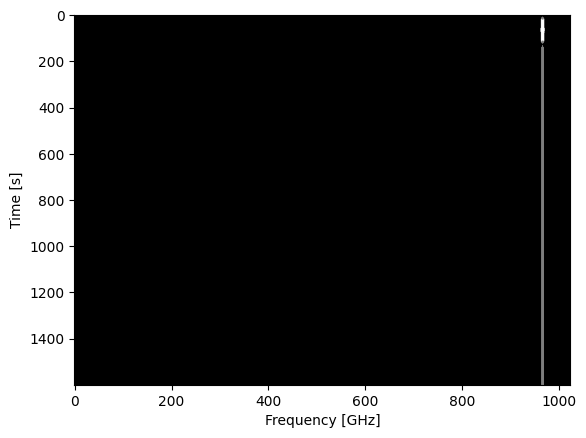

In [50]:
# Plot the edge mask as a waterfall
plt.imshow(anomalies, cmap="gray", aspect="auto")
#plt.colorbar(label="Edge Presence")
plt.xlabel("Frequency [GHz]")
plt.ylabel("Time [s]")
plt.show()

In [51]:
#PAI
pai = np.max(np.abs(spectra[anomalies]))
print("PAI: ", pai)

PAI:  25.90941


In [52]:
#ASS
# Count rows that have at least one True value
rows_with_anomalies = np.any(anomalies, axis=1)
num_rows_with_anomalies = np.sum(rows_with_anomalies)

# Count columns that have at least one True value
columns_with_anomalies = np.any(anomalies, axis=0)
num_columns_with_anomalies = np.sum(columns_with_anomalies)

# Calculate the effective size considering only rows and columns with anomalies
effective_size = num_rows_with_anomalies * num_columns_with_anomalies

try:
    effective_density = np.sum(anomalies) / effective_size
except Exception as e:
    effective_density = 0

pai = np.max(np.abs(spectra[anomalies]))

ass = pai * effective_density # Anomaly Significance Score
print("ASS: ", ass)

ASS:  9.328983089352


In [53]:
#MMR
mean_intensity = np.mean(np.abs(spectra[anomalies]))

try:
    mmr = pai / mean_intensity
except Exception as e:
    mmr = 0
print("MMR: ", mmr)

MMR:  44.510723


In [54]:
#SNR
intensity_std = np.std(spectra)

try:
    snr = pai / intensity_std
except Exception as e:
    snr = 0
print("SNR: ", snr)

SNR:  191.64635
